# Collection data pipeline

This tutorial follows data from two NeuroAI Studies to a PyTorch-ready batch. We will define and run a collection, annotate input and target layouts, create variable-length segments, extract naturally sized samples, group compatible examples, pad them within a batch, and finally package the workflow as `BICData`.

The tutorial requires the data drive.

| Stage | Result |
| --- | --- |
| `collection.run()` | Event metadata with semantic roles and layout annotations |
| `segmenter.apply(events)` | Temporal windows in a ragged dataset |
| `dataset.prepare()` / `dataset[i]` | Prepared sources / one extracted, naturally sized sample |
| `MetadataBatchSampler` | Indices of compatible samples |
| `RaggedCollator` | A batch padded only to its local maximum |
| `BICData.build()` | Prepared split datasets, loaders, and a resolved data contract |

## 1. Define and run a collection

A `Collection` is a runnable NeuroAI chain with two structural guarantees: `CombineStudies` is its first step and `AssignDataLayouts` is its final step. Here we combine two Studies, prepare sentence targets and splits, then declare SpikeCounts as an input and Sentence as a target. This cell defines the recipe; it does not read the source data yet.

In [1]:
import numpy as np
import pandas as pd

from neuralshed.collection import Collection
from neuralshed.datasets.card_2024.study import Card2024Brain2Text
from neuralshed.datasets.willet_2023.study import Willett2023Sentences
from neuralshed.datasets.utils import dataset_dir
from neuralshed.transforms import (
    AssignDataLayouts, AssignHashSplit, CombineStudies, StandardizeText, ValidateTarget,
)

collection = Collection(
    steps={
        "CombineStudies": CombineStudies(
            chains={
                "card_2024": Card2024Brain2Text(
                    path=dataset_dir("card_2024/data"),
                    query="session_index < 3",
                ),
                "willet_2023": Willett2023Sentences(
                    path=dataset_dir("willet_2023/data"),
                    query="session_index < 30",
                ),
            }
        ),
        "StandardizeText": StandardizeText(
            source="text",
            dest="canonical_text",
            scheme="v1",
        ),
        "ValidateTarget": ValidateTarget(
            condition="type == 'Sentence' and canonical_text != ''",
            dest="target_is_valid",
        ),
        "AssignHashSplit": AssignHashSplit(
            by=["timeline", "start"],
            ratios={"train": 0.8, "val": 0.1, "test": 0.1},
            seed=0.0,
        ),
        "AssignDataLayouts": AssignDataLayouts(
            inputs=("SpikeCounts",),
            targets=("Sentence",),
            group_by=("participant_id", "collection_member", "session",),
        ),
    }
)

pd.DataFrame([
    {"step": name, "operation": type(step).__name__}
    for name, step in collection.steps.items()
])

,step,operation
0,CombineStudies,CombineStudies
1,StandardizeText,StandardizeText
2,ValidateTarget,ValidateTarget
3,AssignHashSplit,AssignHashSplit
4,AssignDataLayouts,AssignDataLayouts


### 1.1 Execute the collection

Running the collection loads both Studies, applies each transform, and validates the declared layouts. SpikeCounts rows receive input layout keys and required Study-authored `n_features`; Sentence rows receive `data_role="target"` and their own target layout keys. `valid_targets()` then selects the target rows that are eligible to become segment triggers.

In [2]:
from neuralshed.transforms import valid_targets

events = collection.run().reset_index(drop=True)
targets = valid_targets(events)

layout_rows = events[events["data_layout_key"] != ""]
print(
    f"{len(events)} events | {len(targets)} valid sentence targets | "
    f"{layout_rows['data_layout_key'].nunique()} routed layouts"
)
targets.groupby("collection_member").size().rename("targets").to_frame()

36233 events | 11817 valid sentence targets | 54 routed layouts


,targets
collection_member,
card_2024,917
willet_2023,10900


Before segmenting, inspect a few target rows. `start` and `duration` locate each sentence on its recording timeline, `canonical_text` is the text we will encode, and `split` records its train/validation/test assignment. Each Sentence trigger carries the target layout key shown here. The corresponding input layout keys remain on the SpikeCounts events that cover the same segment; they are not automatically copied into trigger metadata.

In [3]:
targets[[
    "type", "collection_member", "session", "start", "duration",
    "canonical_text", "split", "data_role", "data_layout_key",
]].head(8)

,type,collection_member,session,start,duration,canonical_text,split,data_role,data_layout_key
2,Sentence,card_2024,t15.2023.08.11,0.0,6.42,bring it closer,train,target,participant_id=braingate2%2FT15/collection_mem...
5,Sentence,card_2024,t15.2023.08.11,0.0,9.62,my family is closer,train,target,participant_id=braingate2%2FT15/collection_mem...
8,Sentence,card_2024,t15.2023.08.11,0.0,9.60,what do they like,test,target,participant_id=braingate2%2FT15/collection_mem...
11,Sentence,card_2024,t15.2023.08.11,0.0,10.04,how is that good,train,target,participant_id=braingate2%2FT15/collection_mem...
14,Sentence,card_2024,t15.2023.08.11,0.0,8.04,need help here,train,target,participant_id=braingate2%2FT15/collection_mem...
17,Sentence,card_2024,t15.2023.08.11,0.0,11.50,yes you have it right,train,target,participant_id=braingate2%2FT15/collection_mem...
20,Sentence,card_2024,t15.2023.08.11,0.0,17.80,i tell you my family is not hungry,train,target,participant_id=braingate2%2FT15/collection_mem...
23,Sentence,card_2024,t15.2023.08.11,0.0,11.78,bring my computer here please,train,target,participant_id=braingate2%2FT15/collection_mem...


### 1.2 Visualize a sample of the collection

We can inspect the collection in its native timeline representation. The complete table spans many recordings, so we randomly select 20 timeline identifiers and retain every event associated with each one.

`viz.explore_events` displays one timeline at a time, with event types arranged in separate lanes. Use the timeline selector and filters to navigate the sample, zoom into a time window, and click an event to inspect it.

In [4]:
from neuralshed import viz

timelines = events["timeline"].dropna().drop_duplicates()
selected = timelines.sample(n=min(20, len(timelines)), random_state=0)
sampled_events = events.loc[events["timeline"].isin(selected)].reset_index(drop=True)

explorer = viz.explore_events(events=sampled_events)
explorer

### 1.3 Inspect the collection’s data layouts

`data_layout_key` identifies events that share the metadata selected by `AssignDataLayouts`, plus their event type. Here, participant, collection member, and session distinguish layouts that may require different model adapters or heads.

The key describes **how an event should be routed**, not its number of channels or its number of occurrences. Many events can therefore share one key. The summary keeps the grouping columns visible instead of displaying the encoded keys: each row corresponds to one layout and reports how many event rows use it. Differences also reflect how each Study stores data—for example, one continuous neural event per session versus one neural event per trial.

In [5]:
(
    layout_rows.groupby(
        [*collection.layout_step.group_by, "type", "data_role"],
        dropna=False,
    )
    .agg(n_events=("type", "size"), n_features=("n_features", "first"))
    .reset_index()
)

,participant_id,collection_member,session,type,data_role,n_events,n_features
0,braingate2/T12,willet_2023,t12.2022.04.28,Sentence,target,300,<NA>
1,braingate2/T12,willet_2023,t12.2022.04.28,SpikeCounts,input,15,256
2,braingate2/T12,willet_2023,t12.2022.05.05,Sentence,target,380,<NA>
3,braingate2/T12,willet_2023,t12.2022.05.05,SpikeCounts,input,19,256
4,braingate2/T12,willet_2023,t12.2022.05.17,Sentence,target,490,<NA>
5,braingate2/T12,willet_2023,t12.2022.05.17,SpikeCounts,input,24,256
6,braingate2/T12,willet_2023,t12.2022.05.19,Sentence,target,250,<NA>
7,braingate2/T12,willet_2023,t12.2022.05.19,SpikeCounts,input,12,256
8,braingate2/T12,willet_2023,t12.2022.05.24,Sentence,target,475,<NA>
9,braingate2/T12,willet_2023,t12.2022.05.24,SpikeCounts,input,13,256


## 2. Build a ragged, metadata-rich dataset

The collection has produced event metadata, but no per-trial tensors yet. Each valid `Sentence` now becomes a segment trigger. `duration=None` tells the segmenter to use that sentence's duration, so short and long trials retain different time lengths. The two named extractors define what a sample will expose: `spikes` as neural features and `target` as character IDs.

Neuralset's `Segmenter.apply()` determines the temporal windows from event metadata and normally returns a `SegmentDataset`. Our local `RaggedSegmenter` preserves that native windowing behavior but returns a `RaggedSegmentDataset`, whose items are not globally padded.

`metadata_columns` preserves selected trigger columns alongside each sample. We retain the split, target layout key, and the collection grouping columns so later components can inspect or group samples without extracting their arrays.

`prepare()` reads and caches the extractor sources. Actual per-window extraction happens when `dataset[i]` is requested, after segmentation and before collation. The resulting dataset represents one naturally sized item per valid target.

In [6]:
from neuralshed.dataloader import RaggedSegmenter
from neuralshed.extractors import CharacterEncoder, NeuralFeatureExtractor

segmenter = RaggedSegmenter(
    extractors={
        "spikes": NeuralFeatureExtractor(
            event_types="SpikeCounts",
            target_unit="Hz",
            aggregation="cat",
        ),
        "target": CharacterEncoder(
            event_types="Sentence",
            text_field="canonical_text",
            aggregation="trigger",
        ),
    },
    trigger_query="target_is_valid == True",
    duration=None,  # each segment inherits its sentence duration
    metadata_columns=(
        *collection.layout_step.group_by,
        "dataset_id",
        "timeline",
        "split",
        "canonical_text",
        "data_role",
        "data_layout_key",
    ),
)

# Build the temporal windows
dataset = segmenter.apply(events)

# Prepare and cache the extractor source data
dataset.prepare()

dataset

2026-09-16 13:45:37 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
2026-09-16 13:45:37 - INFO - neuralset.extractors.base:192 - Processing to native frequency in NeuralFeatureExtractor.prepare: 50.0Hz
100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 1223/1223 [01:11<00:00, 17.15it/s]
2026-09-16 13:46:48 - INFO - neuralset.dataloader:222 - Preparing extractor: CharacterEncoder


RaggedSegmentDataset(11817 segments, extractors: spikes, target, metadata: participant_id, collection_member, session, dataset_id, timeline, split, canonical_text, data_role, data_layout_key)

Indexing the dataset performs extraction for one temporal window and returns a `SegmentSample`: naturally shaped extractor tensors, its native `Segment`, and the selected trigger metadata. The table confirms that there is no batch dimension and no padding yet.

In [7]:
sample = dataset[10]
print(sample.segment)
print("\nTrigger metadata:")
print(pd.Series(sample.metadata).to_string())

pd.DataFrame([
    {"field": name, "shape": tuple(tensor.shape), "dtype": str(tensor.dtype)}
    for name, tensor in sample.data.items()
]).set_index("field")

Segment(start=0.0, duration=16.54, timeline='Card2024Brain2Text:block=2,date=2023-08-11,original_split=train,post_implant_day=25,session=t15.2023.08.11,subject=T15,task_condition=attempted,trial_id=10', _trigger_idx=21)

Trigger metadata:
participant_id                                          braingate2/T15
collection_member                                            card_2024
session                                                 t15.2023.08.11
dataset_id                                                   card_2024
timeline             Card2024Brain2Text:block=2,date=2023-08-11,ori...
split                                                            train
canonical_text                      tell my family they are not hungry
data_role                                                       target
data_layout_key      participant_id=braingate2%2FT15/collection_mem...


,shape,dtype
field,,
spikes,"(256, 827)",torch.float32
target,"(34,)",torch.int64


### 2.1 Inspect sentence durations

Sentence durations determine how many neural time bins are extracted for each sample. `ValidateTarget` has already removed empty text targets, so the empty-target count should be zero. The duration summary and histogram show why the dataset needs a variable-length boundary.

Empty canonical targets: 0
min     1.46
25%     4.60
50%     6.04
75%     7.88
max    35.54
Name: duration, dtype: float64


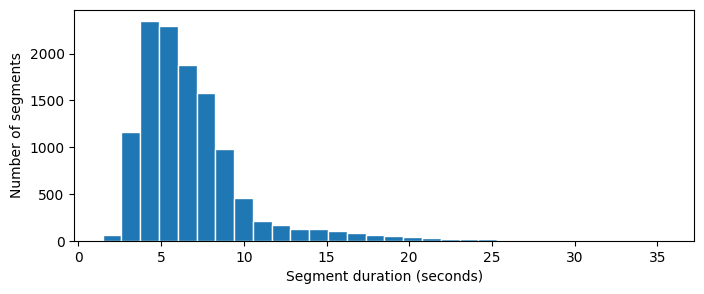

In [8]:
triggers = dataset.triggers
durations = triggers["duration"].to_numpy()
empty_targets = triggers["canonical_text"].fillna("").str.len().eq(0).sum()

print(f"Empty canonical targets: {empty_targets}")
print(triggers["duration"].describe()[["min", "25%", "50%", "75%", "max"]])
ax = triggers["duration"].plot.hist(bins=30, figsize=(8, 3), edgecolor="white")
_ = ax.set(xlabel="Segment duration (seconds)", ylabel="Number of segments")

### 2.2 Inspect samples

We select four samples at evenly spaced ranks in the duration distribution, from shortest to longest. Spike tensors have shape `(channels, time)` and targets have shape `(characters,)`. The changing lengths are preserved exactly: there is no batch dimension and no padding yet.

In [9]:
order = np.argsort(durations)
rank_positions = np.linspace(0, len(order) - 1, 4, dtype=int)
positions = order[rank_positions]

rows = []
for position in positions:
    sample = dataset[int(position)]
    rows.append({
        "member": sample.metadata["collection_member"],
        "text": sample.metadata["canonical_text"],
        "duration_s": sample.segment.duration,
        "spikes": tuple(sample.data["spikes"].shape),
        "target": tuple(sample.data["target"].shape),
    })

pd.DataFrame(rows)

,member,text,duration_s,spikes,target
0,willet_2023,yes,1.46,"(256, 73)","(3,)"
1,willet_2023,two fifty or something,5.04,"(256, 252)","(22,)"
2,willet_2023,so how do you avoid these problems,7.22,"(256, 361)","(34,)"
3,willet_2023,i wish i knew how to swim,35.54,"(256, 1777)","(25,)"


## 3. Group and collate samples into a batch

Training and evaluation must remain separate, so we first select a training-only dataset view. The `MetadataBatchSampler` then chooses compatible sample indices from that view without loading tensors. In this example, reusing `collection.layout_step.group_by` keeps participant, collection member, and session identical within each batch; that is sufficient because each such group has one relevant 256-feature SpikeCounts stream. More complex collections may require a stricter input-layout signature.

The dataset extracts the selected samples, after which `RaggedCollator` pads each configured variable axis only to that batch's maximum and stacks the tensors. The resulting `RaggedBatch` preserves `.data`, `.segments`, original `.lengths`, and `.metadata`.

In [10]:
from torch.utils.data import DataLoader

from neuralshed.dataloader import (
    MetadataBatchSampler, PadSpec, RaggedCollator,
)

train_dataset = dataset.select(dataset.metadata["split"].eq("train"))

batch_sampler = MetadataBatchSampler(
    dataset=train_dataset,
    group_by=collection.layout_step.group_by,
    batch_size=4,
    shuffle=False,
)
loader = DataLoader(
    dataset=train_dataset,
    batch_sampler=batch_sampler,
    collate_fn=RaggedCollator(fields={
        "spikes": PadSpec(axis=-1, pad_value=0),
        "target": PadSpec(axis=0, pad_value=0),
    }),
)
batch = next(iter(loader))

print(batch)
print()
print("Batch metadata:")
pd.DataFrame(batch.metadata)

RaggedBatch(4 segments, 6.42-10.04s, shapes: spikes: 4, 256, 502; target: 4, 19, lengths: spikes: 321-502; target: 14-19)

Batch metadata:


,participant_id,collection_member,session,dataset_id,timeline,split,canonical_text,data_role,data_layout_key
0,braingate2/T15,card_2024,t15.2023.08.11,card_2024,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",train,bring it closer,target,participant_id=braingate2%2FT15/collection_mem...
1,braingate2/T15,card_2024,t15.2023.08.11,card_2024,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",train,my family is closer,target,participant_id=braingate2%2FT15/collection_mem...
2,braingate2/T15,card_2024,t15.2023.08.11,card_2024,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",train,how is that good,target,participant_id=braingate2%2FT15/collection_mem...
3,braingate2/T15,card_2024,t15.2023.08.11,card_2024,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",train,need help here,target,participant_id=braingate2%2FT15/collection_mem...


### 3.1 Use lengths and masks

Padding values do not indicate validity: a real spike-count bin can also be zero. A training routine therefore uses the original lengths and derived masks explicitly:

- Transformers receive `batch.padding_mask("spikes")`.
- CTC input lengths are derived from `batch.lengths["spikes"]` after the model's temporal downsampling.
- CTC target lengths come directly from `batch.lengths["target"]`.
- Per-time-step losses select valid positions with `batch.valid_mask("spikes")`.

In a padding mask, `True` means that position is padding and must be ignored.

In [11]:
spike_padding = batch.padding_mask("spikes")
print("padded spike shape:", tuple(batch.data["spikes"].shape))
print("padding-mask shape:", tuple(spike_padding.shape))

pd.DataFrame({
    "spike_bins": batch.lengths["spikes"].tolist(),
    "target_characters": batch.lengths["target"].tolist(),
    "padded_spike_bins": spike_padding.sum(dim=1).tolist(),
})

padded spike shape: (4, 256, 502)
padding-mask shape: (4, 502)


,spike_bins,target_characters,padded_spike_bins
0,321,15,181
1,481,19,21
2,502,16,0
3,402,14,100


### 3.2 Recover the events behind a batch

Every batch retains its native `Segment` objects. Through them, `batch.events` recovers the collection event rows spanned by those segments—here, the SpikeCounts inputs and Sentence targets for four trials. This is a batch-local event view, not the collection's complete events dataframe.

In [12]:
batch.events[[
    "type", "collection_member", "session", "timeline",
    "start", "duration", "data_role", "data_layout_key",
]]

,type,collection_member,session,timeline,start,duration,data_role,data_layout_key
0,SpikeCounts,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,6.42,input,participant_id=braingate2%2FT15/collection_mem...
2,Sentence,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,6.42,target,participant_id=braingate2%2FT15/collection_mem...
3,SpikeCounts,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,9.62,input,participant_id=braingate2%2FT15/collection_mem...
5,Sentence,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,9.62,target,participant_id=braingate2%2FT15/collection_mem...
9,SpikeCounts,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,10.04,input,participant_id=braingate2%2FT15/collection_mem...
11,Sentence,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,10.04,target,participant_id=braingate2%2FT15/collection_mem...
12,SpikeCounts,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,8.04,input,participant_id=braingate2%2FT15/collection_mem...
14,Sentence,card_2024,t15.2023.08.11,"Card2024Brain2Text:block=2,date=2023-08-11,ori...",0.0,8.04,target,participant_id=braingate2%2FT15/collection_mem...


## 4. Package the pipeline as `BICData`

We assembled the collection, segmenter, sampler, and collator manually above so each boundary was visible. `BICData` packages those same pieces—the executable collection, ragged segmenter, metadata grouping, padding policy, and loader settings—as one validated and serializable configuration. Because `MetadataBatchSampler` forms the batches, its configuration owns `batch_size`; `BICData` retains DataLoader-level settings such as `num_workers` and which splits shuffle.

Calling `build()` reconstructs the data path from that configuration: it runs the collection, creates and prepares one ragged dataset, selects each requested split, and constructs its `DataLoader`. Previously prepared extractor sources can still be reused through their caches.

In [13]:
from neuralshed.data import BICData, MetadataBatchSamplerConfig

bic_data = BICData(
    collection=collection,
    segmenter=segmenter,
    batch_sampler=MetadataBatchSamplerConfig(
        group_by=collection.layout_step.group_by,
        batch_size=4,
        seed=0,
    ),
    num_workers=0,
)

pd.Series({
    "configuration": type(bic_data).__name__,
    "collection_steps": tuple(collection.steps),
    "extractor_fields": tuple(segmenter.extractors),
    "batch_group_by": bic_data.batch_sampler.group_by,
    "batch_size": bic_data.batch_sampler.batch_size,
    "splits": bic_data.splits,
    "shuffle_splits": bic_data.shuffle_splits,
})

configuration                                                 BICData
collection_steps    (CombineStudies, StandardizeText, ValidateTarg...
extractor_fields                                     (spikes, target)
batch_group_by           (participant_id, collection_member, session)
batch_size                                                          4
splits                                             (train, val, test)
shuffle_splits                                               (train,)
dtype: object

`build()` returns a `BuiltData` object rather than hiding the intermediate data. Its full dataset is prepared once, `split_datasets` and `loaders` expose each requested split, and `contract` records collection-wide facts about the named fields, roles, observed layouts, feature widths, padding, and grouping. Indexing the result by a split is a shortcut for selecting that loader.

The contract describes the layouts available to the pipeline; it is not yet the per-sample input-routing map a model adapter will eventually consume. Text targets show `not applicable` for feature widths because they are variable-length token sequences rather than dense feature arrays.

In [14]:
built = bic_data.build()
train_batch = next(iter(built["train"]))

print(built)
print("loader splits:  ", tuple(built.loaders))
print("batch grouping: ", built.contract.batch_group_by)
print("training batch: ", train_batch)

contract_rows = []
for name, field in built.contract.fields.items():
    widths = tuple(sorted(set(field.feature_widths.values())))
    contract_rows.append({
        "field": name,
        "roles": field.roles,
        "n_layouts": len(field.layout_keys),
        "feature_widths": widths or "not applicable",
        "padding": field.padding,
    })

pd.DataFrame(contract_rows).set_index("field")

2026-09-16 13:47:11 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
2026-09-16 13:47:11 - INFO - neuralset.extractors.base:192 - Processing to native frequency in NeuralFeatureExtractor.prepare: 50.0Hz
2026-09-16 13:47:11 - INFO - neuralset.dataloader:222 - Preparing extractor: CharacterEncoder


BuiltData(11817 segments; splits: train=9497, val=1175, test=1145; fields: spikes, target)
loader splits:   ('train', 'val', 'test')
batch grouping:  ('participant_id', 'collection_member', 'session')
training batch:  RaggedBatch(4 segments, 3.44-10.24s, shapes: spikes: 4, 256, 512; target: 4, 48, lengths: spikes: 172-512; target: 17-48)


,roles,n_layouts,feature_widths,padding
field,,,,
spikes,"(input,)",27,"(256,)","PadSpec(axis=-1, pad_value=0)"
target,"(target,)",27,not applicable,"PadSpec(axis=0, pad_value=0)"


### 4.1 Inspect one split loader

Training code normally keeps only the loader it needs. `BICData.build()` selects the split **before** constructing its sampler, so this batch is guaranteed to contain training samples only. The distinct grouping rows also confirm that every sample shares the configured participant, collection member, and session.

In [15]:
batch_metadata = pd.DataFrame(train_batch.metadata)
group_columns = list(built.contract.batch_group_by)

print("Distinct grouping values:")
print(batch_metadata[group_columns + ["split"]].drop_duplicates().to_string(index=False))
batch_metadata[["canonical_text", *group_columns, "split"]]

Distinct grouping values:
participant_id collection_member        session split
braingate2/T12       willet_2023 t12.2022.07.27 train


,canonical_text,participant_id,collection_member,session,split
0,you are not right,braingate2/T12,willet_2023,t12.2022.07.27,train
1,it's right there at the very foot of the rockies,braingate2/T12,willet_2023,t12.2022.07.27,train
2,my husband's retired,braingate2/T12,willet_2023,t12.2022.07.27,train
3,they both cooperate together,braingate2/T12,willet_2023,t12.2022.07.27,train


## Takeaway

At this boundary:

- the collection owns event semantics, target validity, splits, and layout annotations;
- the ragged dataset owns temporal windows and naturally sized extracted samples;
- the sampler owns which compatible samples form a batch;
- the collator owns batch-local padding, lengths, and masks; and
- `BuiltData` exposes the split loaders and collection-wide data contract.

Model-specific input routing and conversion from `RaggedBatch` to the eventual BIC model batch remain a separate next layer.